# Спрос на велосипеды в городском прокате
## 1. Описание данных

Я выбрал данные велопроката Capital Bikeshare за 2011–2012 годы.

В файле `hour.csv` каждая строка описывает один час работы проката.
В таблице есть час суток, день недели, температура, влажность и сведения о погоде.
Столбец `cnt` показывает общее число аренд за этот час.

Источник данных: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

## 2. Вопросы исследования

1. Как различается среднее число аренд за час в разные сезоны?
2. В какие часы суток среднее число аренд самое высокое?
3. В праздничные дни среднее число аренд за час выше или ниже, чем в непраздничные?

## 3. Первичный анализ

In [1]:
# Встроенная копия hour.csv из UCI (gzip + base64).
CSV_DATA = (
    "..."
)

In [2]:
import base64
import gzip
from io import BytesIO
import pandas as pd

csv_bytes = gzip.decompress(base64.b64decode(CSV_DATA))
df = pd.read_csv(BytesIO(csv_bytes))
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
df.shape  # Узнаем размерность датасета

(17379, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [5]:
df.describe()  # Статистика числовых столбцов

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [6]:
df.isna().sum()  # Количество пропусков в каждом столбце. В нашем случае - пропусков нет

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [7]:
df.nunique() # Уникальные знгачения в столбцах

instant       17379
dteday          731
season            4
yr                2
mnth             12
hr               24
holiday           2
weekday           7
workingday        2
weathersit        4
temp             50
atemp            65
hum              89
windspeed        30
casual          322
registered      776
cnt             869
dtype: int64

In [8]:
df.duplicated().sum()  # Просмотр полных копий

np.int64(0)

In [9]:
df.duplicated(subset=["dteday", "hr"]).sum()

np.int64(0)

Каждая строка таблицы описывает один час работы велопроката. В выбранных для анализа столбцах пропусков нет, повторных записей за одну и ту же дату и час не обнаружено. Сезоны, часы и праздники закодированы в ожидаемых пределах, число аренд неотрицательно. По результатам этих проверок данные готовы к анализу.

## 4. Визуализация

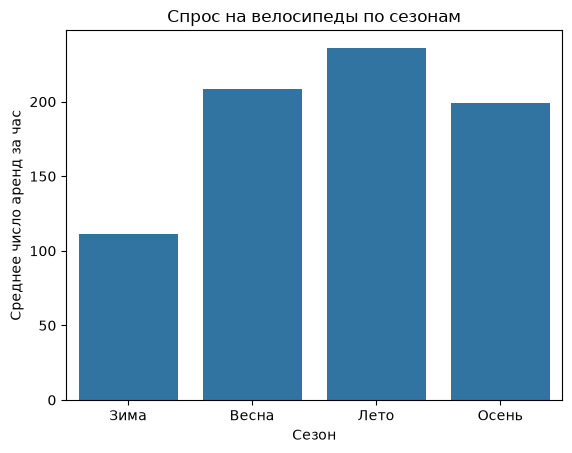

In [10]:
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt


df_by_season = df.groupby("season", as_index=False)["cnt"].mean()

names = {1: "Зима", 2: "Весна", 3: "Лето", 4: "Осень"}
df_by_season["Сезон"] = df_by_season["season"].map(names)


ax = sns.barplot(data=df_by_season, x="Сезон", y="cnt")
ax.set(title="Спрос на велосипеды по сезонам", ylabel="Среднее число аренд за час")
plt.show()

from IPython.display import HTML, display

def show_plot(fig):
    """Сохранить интерактивный график прямо в выводе ячейки."""
    page = fig.to_html(include_plotlyjs=True)
    packed = base64.b64encode(gzip.compress(page.encode(), mtime=0)).decode()
    # Браузер распаковывает HTML графика внутри отдельного фрейма.
    frame = f"""<script>
    (async () => {{
        const bytes = Uint8Array.from(atob('{packed}'), c => c.charCodeAt(0));
        const stream = new Blob([bytes]).stream().pipeThrough(new DecompressionStream('gzip'));
        const page = await new Response(stream).text();
        document.open();
        document.write(page);
        document.close();
    }})();
    </script>"""
    display(HTML(f'<iframe title="График спроса" style="width:100%;height:470px;border:0" srcdoc="{frame}"></iframe>'))

Летом велосипеды брали чаще всего — в среднем 236 аренд за час, зимой реже всего — 111.
От зимы к лету среднее число аренд растёт, а осенью снижается. Летний показатель примерно в 2,1 раза выше зимнего.
Весна и осень оказались близки по спросу: 208 и 199 аренд за час соответственно.
Сезон стоит учитывать при планировании работы проката. Возможно, часть различий связана с погодой. Это можно проверить отдельно по температуре и осадкам.

In [11]:
df_by_hour = df.groupby("hr", as_index=False)["cnt"].mean().sort_values("hr")
fig = px.line(df_by_hour, x="hr", y="cnt",
              title="Среднее число аренд велосипедов по часам суток",
              labels={"hr": "Часы", "cnt": "Среднее число аренд за час"})
fig.update_layout(title_x=0.5, title_xanchor="center")
show_plot(fig)

Больше всего велосипедов брали с 17:00 до 18:00 — в среднем 461 аренда за час.

На графике видны два пика: утром около 8:00 и вечером около 17:00. Между ними спрос снижается.

Пики различаются по высоте: около 8 утра приходится в среднем 359 аренд за час, а в 5 вечера — примерно на 100 больше.
Такое распределение похоже на ритм поездок на работу и домой, чтобы проверить эту гипотезу, можно сравнить почасовые графики для рабочих и выходных дней.

In [12]:
df.head()

df_by_holiday = df.groupby("holiday", as_index=False)["cnt"].mean()

df_by_holiday["Тип дня"] = df_by_holiday["holiday"].map({0: "Обычный день", 1: "Праздник"})

fig = px.bar(
    df_by_holiday,
    x="Тип дня",
    y="cnt",
    color="Тип дня",
    color_discrete_map={"Обычный день": "green", "Праздник": "red"},
    labels={"cnt": "Среднее число аренд за час"},
    title="Среднее число аренд за час в праздничные и обычные дни",
)
fig.update_layout(title_x=0.5, title_xanchor="center", showlegend=False)
show_plot(fig)

В праздники приходилось в среднем 157 аренд за час, в непраздничные дни — 190.
В праздничные дни средний спрос был примерно на 18% ниже.
Можно было ожидать, что свободное время в праздники приведёт к росту числа поездок. В среднем наблюдалась обратная картина.
Одно из возможных объяснений — в праздники люди заняты иной деятельностью.

## 5. Статистический анализ

In [13]:
df.groupby("season", as_index=False)["cnt"].agg(["mean", "median"]).round(1)

,season,mean,median
0,1,111.1,76.0
1,2,208.3,165.0
2,3,236.0,199.0
3,4,198.9,155.5


In [14]:
df.groupby("hr")["cnt"].mean().sort_values(ascending=False).head(3).round(1) 

hr
17    461.5
18    425.5
8     359.0
Name: cnt, dtype: float64

In [15]:
df.groupby("holiday")["cnt"].agg(["count", "mean", "median"]).round(1)  

,count,mean,median
holiday,,,
0,16879,190.4,144.0
1,500,156.9,97.0


In [16]:
df["temp"].corr(df["cnt"])  # Между температурой воздуха и количеством аренд за час наблюдается умеренная положительная связь (корреляция Пирсона ≈ 0,405). 
                            # В более тёплые часы велосипеды в среднем брали чаще

np.float64(0.4047722757786586)

Меня удивила разница между средним и медианой зимой. В среднем за час велосипеды брали 111,1 раза, хотя в половине зимних часов число аренд не превышало 76. Часы высокого спроса тянут среднее вверх, поэтому для описания обычного зимнего часа полезно смотреть и на медиану.

## 10. Подготовка данных для регрессии

Цель — предсказать число аренд за час (`cnt`) по календарю и погоде. Взяты сезон, час, признаки праздника и рабочего дня, категория погоды, температура, влажность и скорость ветра. Столбцы `casual` и `registered` в сумме дают ответ, поэтому исключены. Номер строки `instant` тоже исключён.

Первые 80% часов по времени идут в обучение, последние 20% — в тест. Температура, влажность и ветер уже нормализованы в исходном файле. Пропуск в новом числовом значении заполняем медианой обучающей выборки. Для категорий создаём индикаторы: например, каждый час суток получает свой столбец.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

categories = ["season", "hr", "holiday", "workingday", "weathersit"]
numbers = ["temp", "hum", "windspeed"]

ordered = df.sort_values(["dteday", "hr"])
X = ordered[categories + numbers]
y = ordered["cnt"]
split = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

columns = ColumnTransformer([
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
    ("number", SimpleImputer(strategy="median"), numbers),
], verbose_feature_names_out=False)

pipeline = Pipeline([("preprocessing", columns)]).set_output(transform="pandas")
train_ready = pipeline.fit_transform(X_train)
test_ready = pipeline.transform(X_test)

print("Train (строки, признаки):", train_ready.shape)
print("Test (строки, признаки):", test_ready.shape)
assert train_ready.columns.equals(test_ready.columns)
assert not test_ready.isna().any().any()

Train (строки, признаки): (13903, 39)
Test (строки, признаки): (3476, 39)


## 11. Проверка на новых часах

Три наблюдения используют исходные единицы измерения и коды. Первое — летнее утро, во втором пропущена температура. В третьем условный новый код погоды 5 имитирует расширение справочника.

In [18]:
new_hours = pd.DataFrame({
    "season":     [3, 1, 4],
    "hr":         [8, 17, 12],
    "holiday":    [0, 1, 0],
    "workingday": [1, 0, 0],
    "weathersit": [1, 2, 5],
    "temp":       [0.713, float("nan"), 0.453],
    "hum":        [0.51, 0.72, 0.63],
    "windspeed":  [0.12, 0.18, 0.21],
})
display(new_hours)

,season,hr,holiday,workingday,weathersit,temp,hum,windspeed
0,3,8,0,1,1,0.713,0.51,0.12
1,1,17,1,0,2,NaN,0.72,0.18
2,4,12,0,0,5,0.453,0.63,0.21


In [19]:
new_ready = pipeline.transform(new_hours)

assert new_ready.columns.equals(train_ready.columns)
assert not new_ready.isna().any().any()
assert new_ready.loc[1, "temp"] == X_train["temp"].median()
weather_columns = [col for col in new_ready if col.startswith("weathersit_")]
assert new_ready.loc[2, weather_columns].sum() == 0

print("Обработано строк:", len(new_ready), "Признаков:", new_ready.shape[1])
display(new_ready[["hr_8", "hr_17", "hr_12", *weather_columns, "temp"]])

Обработано строк: 3 Признаков: 39


,hr_8,hr_17,hr_12,weathersit_1,weathersit_2,weathersit_3,weathersit_4,temp
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.713
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.500
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.453


Показана часть готовых признаков. Во второй строке температура заполнена медианой из train. В третьей строке все индикаторы погоды равны нулю — так кодируется незнакомая категория. Полная таблица находится в `new_ready`.

# Выводы

1. Летом спрос был самым высоким — в среднем 236 аренд за час, зимой самым низким — 111. Разница примерно в 2,1 раза.
2. Пик спроса приходился на 17:00–18:00 — в среднем 461 аренда за час.
3. В праздники в среднем совершали 157 аренд за час, в непраздничные дни — 190. В праздничные дни средний почасовой спрос был примерно на 18% ниже.